# ST10355869

Intel Image dataset
Vishal Shah and Neha Sajnani, “Multi-Class Image Classification using CNN and Tflite,” International Journal of Research in Engineering, Science and Management, vol. 3, no. 11, Nov. 2020. https://www.kaggle.com/datasets/puneet6060/intel-image-classification

# Setup

In [ ]:
#install the needed imports
%pip install pyspark tensorflow pandas matplotlib seaborn scikit-learn Pillow numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Imports

In [ ]:
from pyspark.sql import SparkSession  


#import tensflow packages for model training
import tensorflow as tf
from tensorflow.keras import layers, Sequential
from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import load_model

from pyspark.sql.functions import col, split, element_at
from pyspark.sql import functions as F

import matplotlib.pyplot as plt

from urllib.parse import urlparse, unquote
import pandas as pd
import random
from PIL import Image
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import numpy as np 
import seaborn as sns


import os
from tensorflow.keras.models import load_model

## Spark Session

In [ ]:
#initialise spark session
spark = (
    SparkSession.builder
    .appName("PDAN8412_P3")
    .config("spark.memory.offHeap.enabled", "true")
    .config("spark.memory.offHeap.size", "10g")
    .getOrCreate()
)

## Reading the folders

ApacheSpark, “Data sources,” 2026.[Online]. Available: https://spark.apache.org/docs/latest/ml-datasource.html

H. Kamatala, “PySpark- Reading all Files from Nested folders Recursively,” https://medium.com/@k.harivara/pyspark-reading-all-files-from-nested-folders-recursively-65ba868201ed.

In [ ]:
base = "part 3 dataset"

#get the dimenions of the images in the training data
image_df_train = (
    spark.read.format("image")
    .option("recursiveFileLookup", "true")
      #drop invalid images that may be corrupted, these are null values
    .option("dropInvalid", True)
    .load(f"{base}\\seg_train")
    .select(
        "image",
        "image.origin",
        "image.height",
        "image.width",
        "image.nChannels",
        "image.mode"
    )
    .withColumn("label", element_at(split(col("origin"), r"[/\\]"), -2))
)
#get the relevant data for the test data
image_df_test = (
    spark.read.format("image")
    .option("recursiveFileLookup", "true")
    .option("dropInvalid", True)
    .load(f"{base}\\seg_test")
    .select(
        "image",
        "image.origin",
        "image.height",
        "image.width",
        "image.nChannels",
        "image.mode"
    )
    .withColumn("label", element_at(split(col("origin"), r"[/\\]"), -2))
)
#check that the data has been loaded to dataframesw
print("Training Data")
image_df_train.printSchema()
print("Test Data")
image_df_test.printSchema()

Training Data
root
 |-- image: struct (nullable = true)
 |    |-- origin: string (nullable = true)
 |    |-- height: integer (nullable = true)
 |    |-- width: integer (nullable = true)
 |    |-- nChannels: integer (nullable = true)
 |    |-- mode: integer (nullable = true)
 |    |-- data: binary (nullable = true)
 |-- origin: string (nullable = true)
 |-- height: integer (nullable = true)
 |-- width: integer (nullable = true)
 |-- nChannels: integer (nullable = true)
 |-- mode: integer (nullable = true)
 |-- label: string (nullable = true)

Test Data
root
 |-- image: struct (nullable = true)
 |    |-- origin: string (nullable = true)
 |    |-- height: integer (nullable = true)
 |    |-- width: integer (nullable = true)
 |    |-- nChannels: integer (nullable = true)
 |    |-- mode: integer (nullable = true)
 |    |-- data: binary (nullable = true)
 |-- origin: string (nullable = true)
 |-- height: integer (nullable = true)
 |-- width: integer (nullable = true)
 |-- nChannels: integer (

## Preprocess

### Duplicates

to check for duplicates in images, they can be hashed and the numbers compared to see duplicates


In [ ]:
#add a column with the hashed data
df_hashed = image_df_train.withColumn("image_hash", F.sha2("image.data", 256))

# Group to see which hashes appear more than once
duplicate_hashes = (
    df_hashed.groupBy("image_hash")
    #counts the number of duplicates
    .agg(F.count("*").alias("count"))
    #filters if count is greater than 1 showing duplicates
    .filter(F.col("count") > 1)
)
#number of duplicate images
num_duplicates = duplicate_hashes.count()
print(f"Number of duplicate images: {num_duplicates}")



Number of duplicate images: 15


In [ ]:
#count number of images before and after dropping duplicates to make sure the duplicates are dropped
before_drop_duplicates = image_df_train.count()
image_df_train = df_hashed.dropDuplicates(["image_hash"])
after_drop_duplicates = image_df_train.count()
print(f"Number of images before dropping duplicates: {before_drop_duplicates}")
print(f"Number of images after dropping duplicates: {after_drop_duplicates}")

Number of images before dropping duplicates: 14034
Number of images after dropping duplicates: 14019


duplicates will be dropped


### split duplicates
These are duplicate in the training set, since the test set is already split, a check for duplicates between the 2 sets will be needed so that there are not copies of the same image.

In [7]:
train_hashes = df_hashed.select("image_hash").distinct()
#hash test images using same hashing type
test_hashed = image_df_test.withColumn("image_hash", F.sha2("image.data", 256))
#joins the test and train hashed imagaes
leaked = (test_hashed.join(train_hashes, on="image_hash", how="inner"))

print(f"Test images that also appear in train: {leaked.count()}")
leaked.select("origin", "label", "image_hash").show(truncate=False)

Test images that also appear in train: 3
+--------------------------------------------------------------------------------------------------------------------------+---------+----------------------------------------------------------------+
|origin                                                                                                                    |label    |image_hash                                                      |
+--------------------------------------------------------------------------------------------------------------------------+---------+----------------------------------------------------------------+
|file:///C:/varsity/PostGrad/Semester%202/PDAN8412/Part%203/Part%203%20code/part%203%20dataset/seg_test/glacier/21469.jpg  |glacier  |3aee9b36fe888fce2f536faff91df84a51d02c4edf92d85e220e151c60313304|
|file:///C:/varsity/PostGrad/Semester%202/PDAN8412/Part%203/Part%203%20code/part%203%20dataset/seg_test/buildings/20805.jpg|buildings|07e348fc4393b15a4dc1b76ed


since there are duplicates between the sets, i will remove them from the test set so that the model can still train on them


In [8]:

#drop from the test set
image_df_test = (test_hashed.join(train_hashes, on="image_hash", how="left_anti").drop("image_hash"))

#check the  number of images and see if they are removed
image_df_test.groupBy("label").count().orderBy("label").show()
print(f"Total number of test images: {image_df_test.count()}")



+---------+-----+
|    label|count|
+---------+-----+
|buildings|  436|
|   forest|  474|
|  glacier|  552|
| mountain|  525|
|      sea|  510|
|   street|  500|
+---------+-----+

Total number of test images: 2997


the 3 images were dropped, looking at the label count there was 1 duplicate in buildings, 1 in glacier and 1 in the street class


### Tensor Setup

To allow the use of tensorflos packages in preparing the dataset, a copy of the cleaned dataframe will be created. this allows for the processing to be done in tensor and helps when preparing the data for the model.
AI USE, chat is uploaded in document

In [9]:

#convert to pandas
train_meta = image_df_train.select("origin", "label").toPandas()
test_meta  = image_df_test.select("origin", "label").toPandas()

# Consistent class order for train AND test
classes = sorted(train_meta["label"].unique())     
#dictionary to encode the classes to integer values    
class_to_idx = {c: i for i, c in enumerate(classes)}

train_meta["y"] = train_meta["label"].map(class_to_idx).astype("int32")
test_meta["y"]  = test_meta["label"].map(class_to_idx).astype("int32")



In [ ]:
def to_local(uri: str) -> str:
    p = unquote(urlparse(uri).path)      
    return p.lstrip("/")               

train_meta["path"] = train_meta["origin"].map(to_local)
test_meta["path"]  = test_meta["origin"].map(to_local)


check that the count for the new paths are the same


In [11]:

print(len(train_meta), image_df_train.count())   
print(len(test_meta),  image_df_test.count())      
print(train_meta["label"].value_counts().sort_index())

14019 14019
2997 2997
label
buildings    2191
forest       2269
glacier      2404
mountain     2506
sea          2272
street       2377
Name: count, dtype: int64


# EDA

## Class balance

In [12]:
image_df_train.groupBy("label").count().orderBy("label").show()

+---------+-----+
|    label|count|
+---------+-----+
|buildings| 2191|
|   forest| 2269|
|  glacier| 2404|
| mountain| 2506|
|      sea| 2272|
|   street| 2377|
+---------+-----+



the classes have a relative balance between all classes where they are around 2200-2400

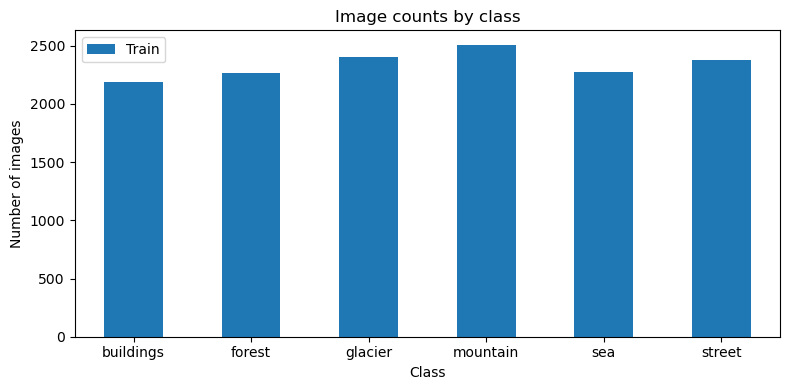

In [13]:

#create a count in spark and convert to pandas for plotting
train_counts = (
    image_df_train.groupBy("label").count()
    .withColumnRenamed("count", "Train")
    .orderBy("label")
    .toPandas()
    .set_index("label")
)
ax = train_counts.plot(kind="bar", figsize=(8, 4))
ax.set_title("Image counts by class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)


plt.tight_layout()
plt.show()

all relatively the same, there are more mountain images in total and the least is buildings but there is no big imbalance between classes that require a need for techniques to balance class weights.

## Test-train  split

the dataset is already split into a train and test set with the relevant labels so checking what the split is and if it can be used for the model or if the data should be combined.

In [14]:
#checking total amount to see the split from download
print(f"Total number of images: {image_df_train.count()}")

Total number of images: 14019


checking the test set for the quantity in it

In [15]:

image_df_test.groupBy("label").count().orderBy("label").show()
print(f"Total number of test images: {image_df_test.count()}")

+---------+-----+
|    label|count|
+---------+-----+
|buildings|  436|
|   forest|  474|
|  glacier|  552|
| mountain|  525|
|      sea|  510|
|   street|  500|
+---------+-----+

Total number of test images: 2997


In [16]:
total_images = image_df_train.count() + image_df_test.count()
print(f"Total number of images: {total_images}")

Total number of images: 17016


In [17]:
test_share = image_df_test.count()/total_images
train_share = image_df_train.count()/total_images

print(f"Share of test images: {test_share:.2%}")
print(f"Share of train images: {train_share:.2%}")

Share of test images: 17.61%
Share of train images: 82.39%


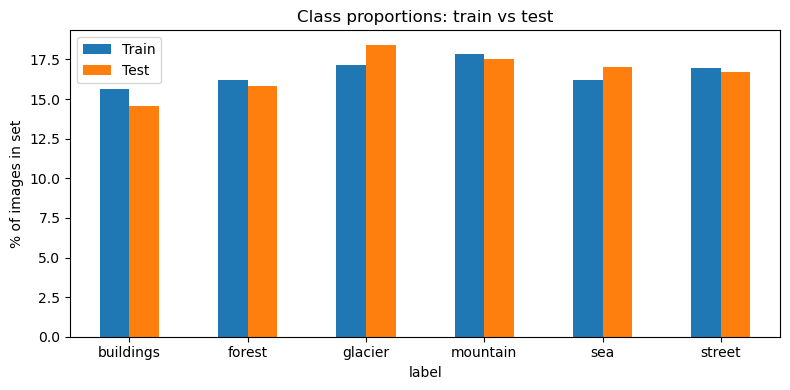

In [ ]:



#convert to pandas so can plot count
tr = image_df_train.groupBy("label").count().toPandas().set_index("label")["count"]
te = image_df_test.groupBy("label").count().toPandas().set_index("label")["count"]

#get the percentage of 
props = pd.DataFrame({
    "Train": tr / tr.sum() * 100,
    "Test":  te / te.sum() * 100
}).sort_index()

ax = props.plot(kind="bar", figsize=(8, 4))
ax.set_title("Class proportions: train vs test")
ax.set_ylabel("% of images in set")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

sufficient split to use the original split, just over a 80/20 split with enough test entries in the test dataset. keeping it seperate will also allow for no data leakage to happen

## Resolution

CNN need consistent resolution for the input data so a check needs to be done to see what resolution these images are

In [20]:
#check the heigh and width of the images in the dataset
train_resolution_count = image_df_train.groupBy("height", "width").count().orderBy(F.desc("count"))
train_resolution_count.show(5)


+------+-----+-----+
|height|width|count|
+------+-----+-----+
|   150|  150|13971|
|   113|  150|    7|
|   111|  150|    3|
|   135|  150|    3|
|   134|  150|    2|
+------+-----+-----+
only showing top 5 rows


the majority of the dimensions are 150x150, to see the exact number of changes the dataset will be filtered to see before and after

checking the percentage of resolutions between the majority and the rest of the count

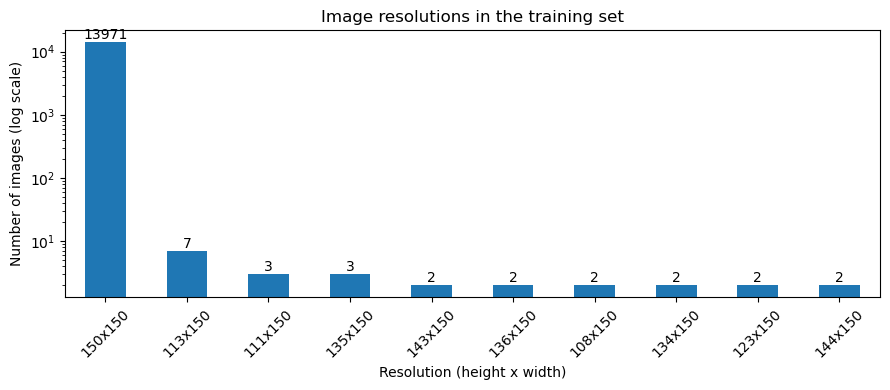

In [21]:
#convert to pandas
res_plot =(image_df_train.groupBy("height", "width").count().orderBy(F.desc("count")).toPandas())
#get the string resolution joined to see labels for the total resolution
res_plot["resolution"] = res_plot["height"].astype(str) + "x" + res_plot["width"].astype(str)
#get the top 10 resolutions
top = res_plot.head(10)


ax = top.plot(kind="bar", x="resolution", y="count", legend=False, figsize=(9, 4))
       
ax.set_title("Image resolutions in the training set")
#logging the y axis(count) as otherwise the majority makes it so other bars cant be see
ax.set_yscale("log")
ax.set_xlabel("Resolution (height x width)")
ax.set_ylabel("Number of images (log scale)")
ax.bar_label(ax.containers[0])  # print the count on each bar
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [22]:
#create a copy of image dataframe to use for exploring
df = image_df_train

In [23]:
before_filter = image_df_train.count()
image_df_train = image_df_train.filter((col("height") == 150) & (col("width") == 150))
print(f"Number of images before filtering: {before_filter}")
print(f"Number of images after filtering: {image_df_train.count()}")

Number of images before filtering: 14019
Number of images after filtering: 13971


In [24]:
print(f"Number of images filtered out: {before_filter - image_df_train.count()}")

Number of images filtered out: 48


48 images were removed from the filter, to keep the size of the dataset these will still be kept since they will be able to be fit to the dimensions before training in tensorflow, this allows for the model to have as much data as possible even if it is only a small amount that would be left out of

In [25]:
#assign the before filtered dataframe to original dataframe 
image_df_train = df

## checking test resolutions

In [26]:
test_resolution_count = image_df_test.groupBy("height", "width").count().orderBy(F.desc("count"))
test_resolution_count.show(5)

+------+-----+-----+
|height|width|count|
+------+-----+-----+
|   150|  150| 2990|
|   131|  150|    1|
|    81|  150|    1|
|   149|  150|    1|
|   141|  150|    1|
+------+-----+-----+
only showing top 5 rows


Plot these to view the different resolutions also

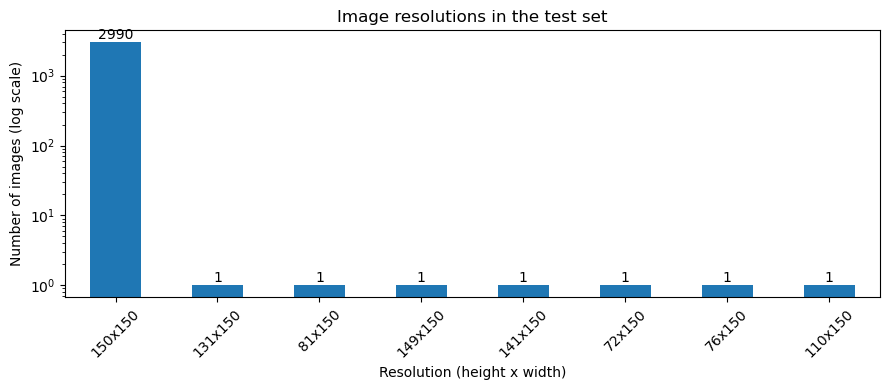

In [27]:
res_plot_test =(image_df_test.groupBy("height", "width").count().orderBy(F.desc("count")).toPandas())
#get the string resolution joined to see labels for the total resolution
res_plot_test["resolution"] = res_plot_test["height"].astype(str) + "x" + res_plot_test["width"].astype(str)
#get the top 10 resolutions
top_test = res_plot_test.head(10)


ax = top_test.plot(kind="bar", x="resolution", y="count", legend=False, figsize=(9, 4))
       
ax.set_title("Image resolutions in the test set")
#logging the y axis(count) as otherwise the majority makes it so other bars cant be see
ax.set_yscale("log")
ax.set_xlabel("Resolution (height x width)")
ax.set_ylabel("Number of images (log scale)")
ax.bar_label(ax.containers[0])  # print the count on each bar
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## Sample Images

using AI, chat will be shown in document added, this was created as a way to view a sample of images in the different classes to see the type of image in each to see if there were any clear patterns before training.

In [ ]:


def show_class_samples(meta_df, n_per_class=5, seed=42):
    classes = sorted(meta_df["label"].unique())
    fig, axes = plt.subplots(len(classes), n_per_class,
                             figsize=(12, 3 * len(classes)), squeeze=False)
    rng = random.Random(seed)

    for i, cls in enumerate(classes):
        paths = meta_df.loc[meta_df["label"] == cls, "path"].tolist()
        picks = rng.sample(paths, min(n_per_class, len(paths)))
        for j, p in enumerate(picks):
            ax = axes[i, j]
            ax.imshow(Image.open(p))
            ax.axis("off")
            if j == 0:
                ax.set_title(cls, fontsize=11, loc="left", fontweight="bold")

    plt.tight_layout()
    plt.show()



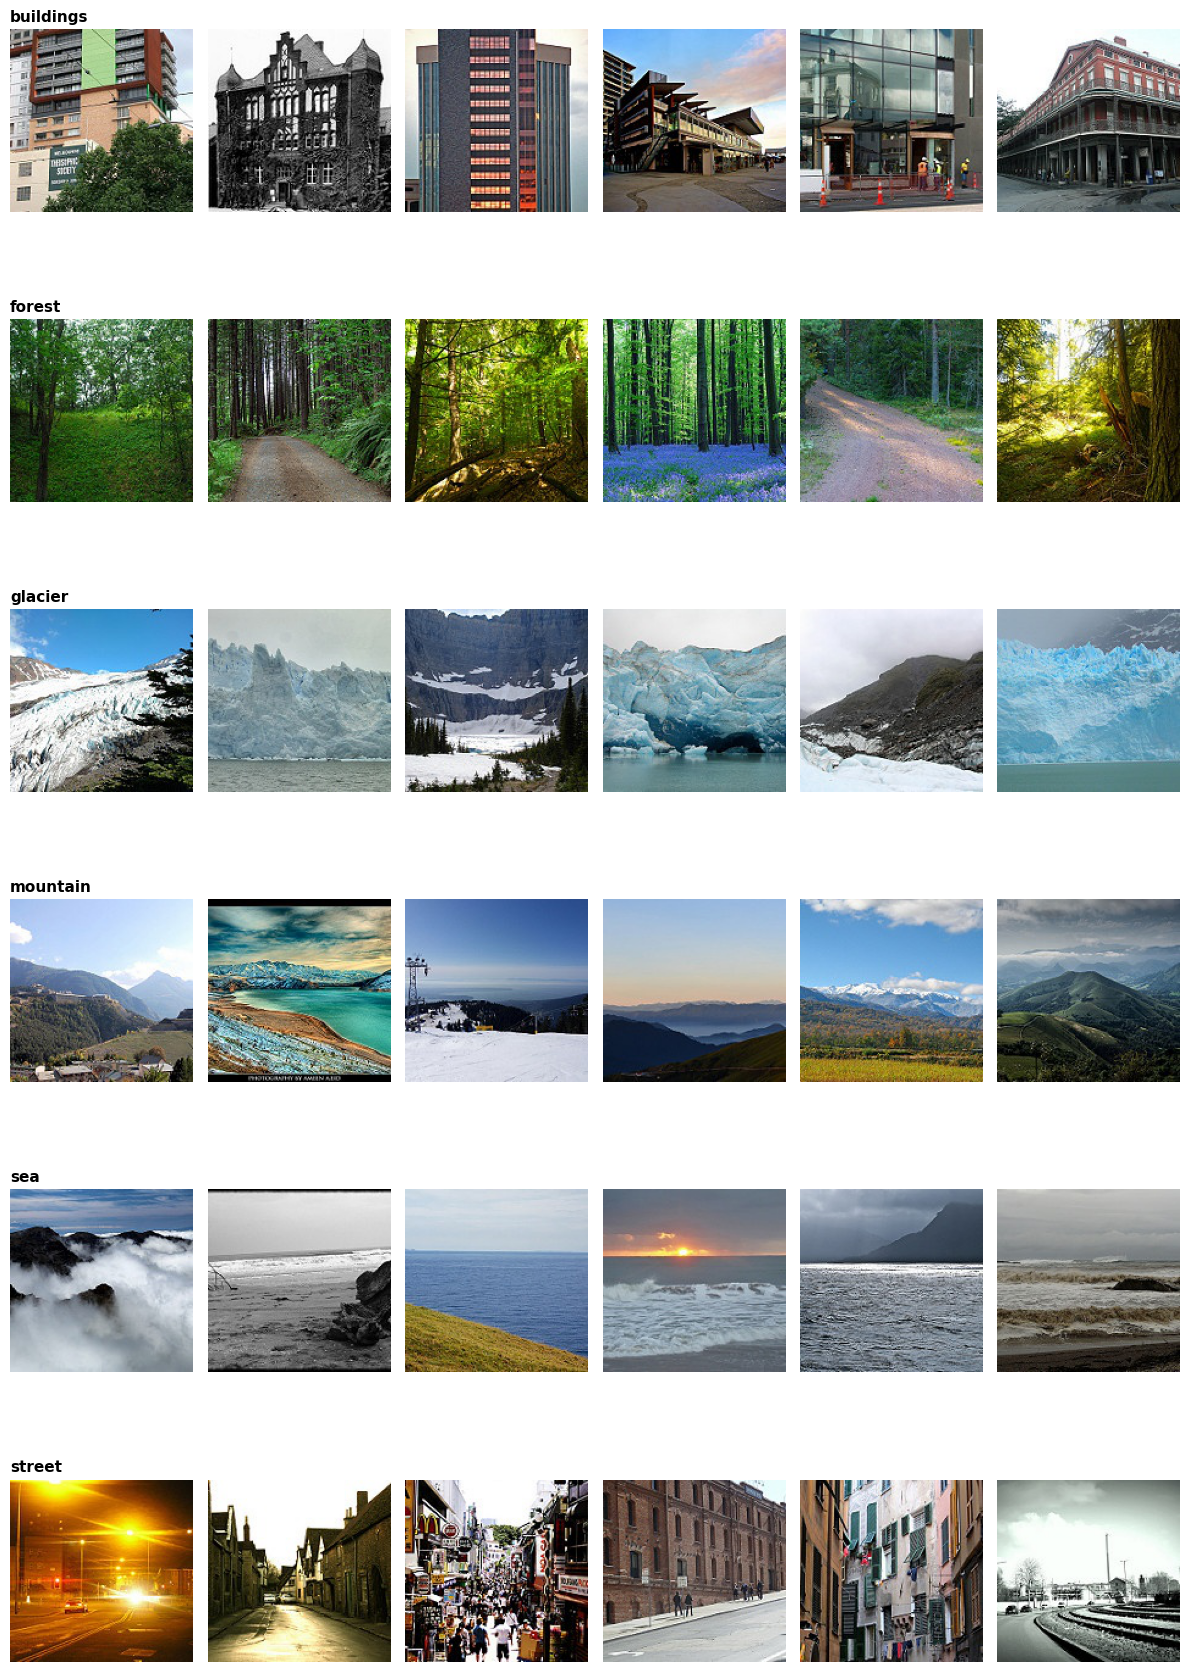

In [ ]:
show_class_samples(train_meta, n_per_class=6)

# CNN Model

This section in the notebook is setting up the data to be used in a model and also setting up the model hyperparamaters.

## data preparation

the training data will be split into training and validation data

In [ ]:

training, validation = train_test_split(train_meta, test_size=0.2, stratify=train_meta["y"], random_state=42)

split data before anything is done so that only the changes will be done to the training split to avoid data leakage.

## preprocess

need to preprocess the data so it is consistent and allows cnn to learn correctly

In [62]:
#setup a pipeline to process the training data
IMG_SIZE=(150,150)
def process_image(path,label):
    # Read the image from the file
    image = tf.io.read_file(path)
    # decode the image
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    #resize the image to the 150x150 resolution
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

#create a dataset table that can be used in tensor model
def make_ds(meta, shuffle=False):
    #gets a dataset using the path and what class it is in
    ds = tf.data.Dataset.from_tensor_slices((meta["path"].values, meta["y"].values))
    if shuffle:
        ds = ds.shuffle(len(meta), seed=42)
    return ds.map(process_image).batch(32)

train_ds = make_ds(training, shuffle=True)
val_ds = make_ds(validation)
test_ds = make_ds(test_meta)

the above code is where the path of the image in the folder and then the label that relates to each class

# Models

## Base Model

TensorFlow, “Module: tf.keras.layers  |  TensorFlow v2.21.0,” 2026. https://www.tensorflow.org/api_docs/python/tf/keras/layers?version=stable.

TensorFlow, “Data augmentation  |  TensorFlow Core,” https://www.tensorflow.org/tutorials/images/data_augmentation#data_augmentation_2.

### layer setup


to enhance the learning capabilities the image data can be augmented to help in creating more training images, this is done by creating copies of the images and changing the angle of the image by flipping it or rotating.

In [ ]:


model = Sequential([
    layers.Input(shape=(150, 150, 3)),     
    #augment the data to help reduce overfitting
    layers.Rescaling(1./255),  
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1), 
    layers.RandomZoom(0.1),              
    #convolutional layers
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    #output layer with 6 nodes for each class
    layers.Dense(6, activation="softmax"),
])

### Fit to data

fit the data to the model and create an early stop incase validation loss increases 3 times, this allows for the model to stop before the validation loss gets bigger

TensorFlow, “tf.keras.callbacks.EarlyStopping  |  TensorFlow v2.16.1,” https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping.

H. Kamatala, “PySpark- Reading all Files from Nested folders Recursively,” https://medium.com/@k.harivara/pyspark-reading-all-files-from-nested-folders-recursively-65ba868201ed.

In [74]:
early_stop = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

model.compile(
    optimizer="adam",                    
    loss="sparse_categorical_crossentropy",  
    metrics=["accuracy"],
)

history = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[early_stop])

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 67s 189ms/step - accuracy: 0.5772 - loss: 1.1180 - val_accuracy: 0.6904 - val_loss: 0.8596
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 64s 183ms/step - accuracy: 0.6663 - loss: 0.8963 - val_accuracy: 0.7147 - val_loss: 0.7909
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 62s 177ms/step - accuracy: 0.7049 - loss: 0.8077 - val_accuracy: 0.6869 - val_loss: 0.9097
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 63s 179ms/step - accuracy: 0.7243 - loss: 0.7567 - val_accuracy: 0.7325 - val_loss: 0.7837
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 64s 183ms/step - accuracy: 0.7519 - loss: 0.6932 - val_accuracy: 0.7382 - val_loss: 0.7604
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 63s 178ms/step - accuracy: 0.7616 - loss: 0.6684 - val_accuracy: 0.7718 - val_loss: 0.7236
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 61s 175ms/step - accuracy: 0.7697 - loss: 0.6463 - val_accuracy: 0.7764 - val_loss: 0.6859
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 167ms/step - accuracy: 0.7800 - loss: 0

### Evaluation

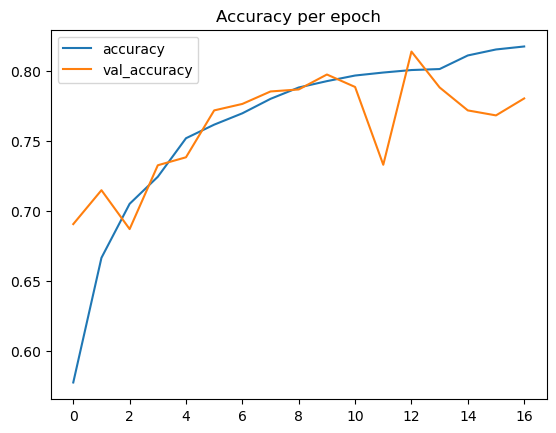

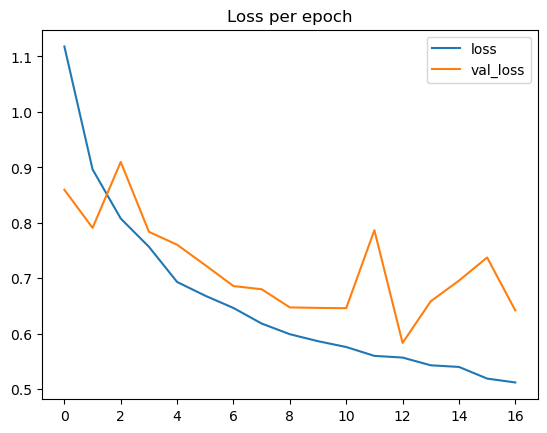

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.8075 - loss: 0.5719
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step
Test accuracy: 0.8075
              precision    recall  f1-score   support

   buildings       0.80      0.77      0.79       436
      forest       0.94      0.95      0.94       474
     glacier       0.80      0.74      0.77       552
    mountain       0.76      0.72      0.74       525
         sea       0.74      0.83      0.78       510
      street       0.82      0.85      0.83       500

    accuracy                           0.81      2997
   macro avg       0.81      0.81      0.81      2997
weighted avg       0.81      0.81      0.81      2997



In [ ]:

hist = pd.DataFrame(history.history)
hist[["accuracy", "val_accuracy"]].plot(title="Accuracy per epoch")
hist[["loss", "val_loss"]].plot(title="Loss per epoch")
plt.show()

test_loss, test_acc = model.evaluate(test_ds)
y_pred = np.argmax(model.predict(test_ds), axis=1)
y_true = test_meta["y"].values
print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true, y_pred, target_names=classes))


## Improved model

to try and improve the model, I created more layers and had the model train for longer. this reason is because the previous model was not completely overfitting or underfitting, it means that training for longer could help improve performance.

In [88]:
model_layer = Sequential([
   layers.Input(shape=(150, 150, 3)),   
     #same augmentation
    layers.Rescaling(1./255),  
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1), 
    layers.RandomZoom(0.1),  
    #convolutional layers  
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    #adding dropout layer 
    layers.Dropout(0.4),
    layers.Dense(6, activation="softmax"),
])

Add a new stop to allow model to train longer

In [89]:
#create new early stopping to see if training for longer will improve accuracy
early_stop_new = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

model_layer.compile(
    optimizer="adam",                    
    loss="sparse_categorical_crossentropy",  
    metrics=["accuracy"],
)
history_layers = model_layer.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=[early_stop_new])

Epoch 1/30


c:\Users\kevin\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 91s 251ms/step - accuracy: 0.5528 - loss: 1.1325 - val_accuracy: 0.6191 - val_loss: 0.9645
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 92s 262ms/step - accuracy: 0.6605 - loss: 0.9037 - val_accuracy: 0.6912 - val_loss: 0.8352
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 89s 254ms/step - accuracy: 0.6976 - loss: 0.8146 - val_accuracy: 0.7493 - val_loss: 0.7177
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 89s 253ms/step - accuracy: 0.7279 - loss: 0.7402 - val_accuracy: 0.7225 - val_loss: 0.8290
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 90s 255ms/step - accuracy: 0.7497 - loss: 0.6809 - val_accuracy: 0.7718 - val_loss: 0.6600
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 90s 257ms/step - accuracy: 0.7658 - loss: 0.6445 - val_accuracy: 0.7718 - val_loss: 0.6605
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 88s 251ms/step - accuracy: 0.7756 - loss: 0.6214 - val_accuracy: 0.7896 - val_loss: 0.5819
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 87s 249ms/step - accuracy: 0.7886 - loss: 0.5830 - val

#### Evaluation

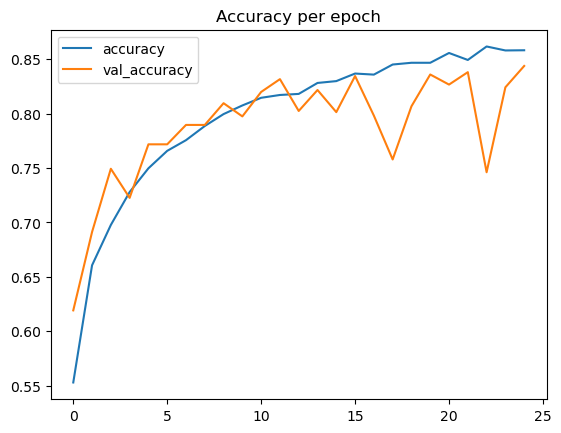

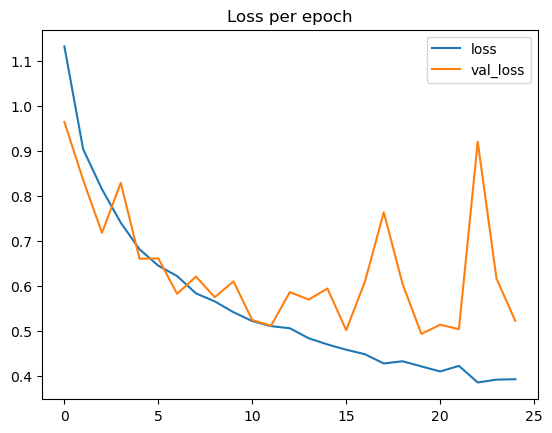

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.8415 - loss: 0.4615
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step
Test accuracy: 0.8415
              precision    recall  f1-score   support

   buildings       0.80      0.88      0.84       436
      forest       0.96      0.97      0.97       474
     glacier       0.88      0.68      0.77       552
    mountain       0.78      0.76      0.77       525
         sea       0.78      0.91      0.84       510
      street       0.87      0.88      0.88       500

    accuracy                           0.84      2997
   macro avg       0.85      0.85      0.84      2997
weighted avg       0.85      0.84      0.84      2997



In [90]:
hist_layer = pd.DataFrame(history_layers.history)
hist_layer[["accuracy", "val_accuracy"]].plot(title="Accuracy per epoch")
hist_layer[["loss", "val_loss"]].plot(title="Loss per epoch")
plt.show()
#get the accuracy and loss of model during training
test_loss, test_acc = model_layer.evaluate(test_ds)
y_pred_layer = np.argmax(model_layer.predict(test_ds), axis=1)
y_true_layer = test_meta["y"].values

print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true_layer, y_pred_layer, target_names=classes))

## save models for final evaluation

In [ ]:



#save the models that will be used in the report
model.save("baseline_cnn.keras")
model_layer.save("moreLayers_cnn.keras")

In [92]:
#load these models
model_baseline  = tf.keras.models.load_model("baseline_cnn.keras")
model_moreLayers = tf.keras.models.load_model("moreLayers_cnn.keras")

get the classification report for these models that will be used in the report

In [ ]:

y_true = test_meta["y"].values

baseline_model = load_model("baseline_cnn.keras")
test_loss, test_acc = baseline_model.evaluate(test_ds)
y_pred_baseline = np.argmax(baseline_model.predict(test_ds), axis=1)

print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true, y_pred_baseline, target_names=classes))

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.8075 - loss: 0.5719
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step
Test accuracy: 0.8075
              precision    recall  f1-score   support

   buildings       0.80      0.77      0.79       436
      forest       0.94      0.95      0.94       474
     glacier       0.80      0.74      0.77       552
    mountain       0.76      0.72      0.74       525
         sea       0.74      0.83      0.78       510
      street       0.82      0.85      0.83       500

    accuracy                           0.81      2997
   macro avg       0.81      0.81      0.81      2997
weighted avg       0.81      0.81      0.81      2997



In [94]:
more_layers_model = load_model("moreLayers_cnn.keras")
test_loss, test_acc = more_layers_model.evaluate(test_ds)
y_pred_more = np.argmax(more_layers_model.predict(test_ds), axis=1)

print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_true, y_pred_more, target_names=classes))

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.8415 - loss: 0.4615
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step
Test accuracy: 0.8415
              precision    recall  f1-score   support

   buildings       0.80      0.88      0.84       436
      forest       0.96      0.97      0.97       474
     glacier       0.88      0.68      0.77       552
    mountain       0.78      0.76      0.77       525
         sea       0.78      0.91      0.84       510
      street       0.87      0.88      0.88       500

    accuracy                           0.84      2997
   macro avg       0.85      0.85      0.84      2997
weighted avg       0.85      0.84      0.84      2997

